# Risk-adjusted survivor functions for two treatments

The Kaplan-Meier estimators of two treatment groups do not take into account the prognostic variables of the patients. An alternative is to fit a Cox model with those variables, stratified by treatment, so each treatment has its own baseline survivor function $\hat S_{0j}(t)$. The risk-adjusted survivor function of treatment $j$ is the average of the estimated survivor functions of its $n_j$ patients:

$$
\bar S_j(t)=\frac{1}{n_j}\sum_{i=1}^{n_j}\hat S_{0j}(t)^{\exp(\hat\beta^Tx_{ij})}.
$$

The data are the survival times, in months, of 38 patients with prostatic cancer treated with a placebo (`treatment` 1) or with DES (`treatment` 2). The prognostic variables are the size of the tumour and the Gleason index, chosen in the notebook on model building.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, CoxPHFitter

In [2]:
# Colors shared by all the plots
GROUP_COLORS = {'Placebo': '#1f4e79', 'DES': '#E69F00'}

## The data

In [3]:
DatOriginal = pd.read_csv("data/prostatic_cancer_treatments.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,patient,treatment,time,status,age,shb,size,index
0,1,1,65,0,67,13.4,34,8
1,2,2,61,0,60,14.6,4,10
2,3,2,60,0,77,15.6,3,8
3,4,1,58,0,64,16.2,6,9
4,5,2,51,0,65,14.1,21,9


In [5]:
DatOriginalPlacebo = DatOriginal[DatOriginal['treatment']==1]
DatOriginalDes = DatOriginal[DatOriginal['treatment']==2]

## The stratified model

In [6]:
cph = CoxPHFitter()
Model = cph.fit(DatOriginal, 'time', 'status', formula='size+index', strata='treatment')

In [7]:
Model.print_summary()

<lifelines.CoxPHFitter: fitted with 38 total observations, 32 right-censored observations>
             duration col = 'time'
                event col = 'status'
                   strata = treatment
      baseline estimation = breslow
   number of observations = 38
number of events observed = 6
   partial log-likelihood = -9.35
         time fit was run = 2026-10-13 02:25:45 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
size       0.07      1.07      0.05           -0.03            0.16                0.97                1.18
index      0.65      1.92      0.34           -0.02            1.33                0.98                3.77

           cmp to    z    p  -log2(p)
covariate                            
size         0.00 1.39 0.16      2.61
index        0.00 1.90 0.06      4.13
---
Concordance = 0.82
Partial AIC = 22.69
log-likelihood ratio test = 7.89 on 2 df
-log2(p) of ll-ratio test = 5.69

## Kaplan-Meier and risk-adjusted estimates

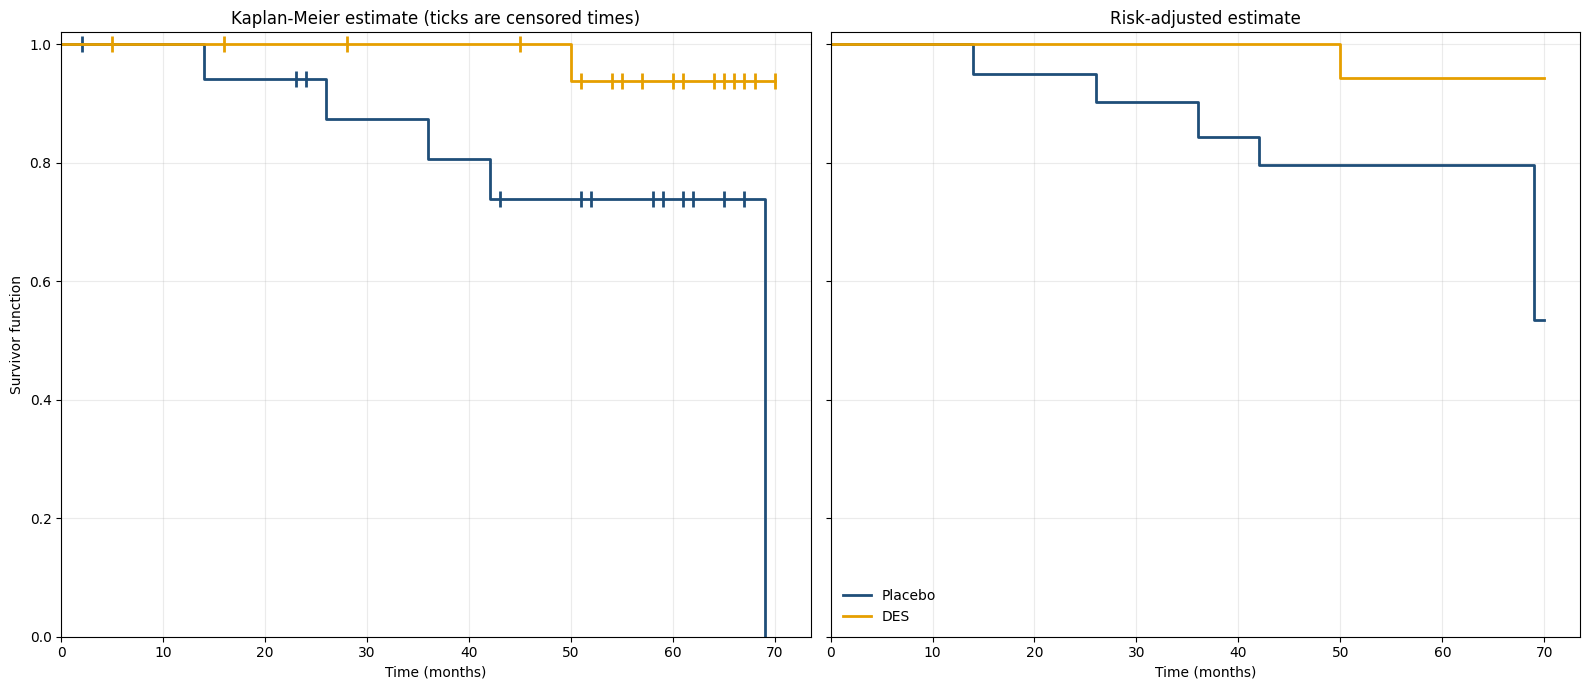

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True) # The subfigures share the same x axis

for (label, color), DatGroup in zip(GROUP_COLORS.items(), [DatOriginalPlacebo, DatOriginalDes]):
    # Unadjusted
    kmf = KaplanMeierFitter()
    kmf.fit(DatGroup['time'], event_observed=DatGroup['status'], label=label)
    surv = kmf.survival_function_.iloc[:, 0]
    censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
    ax[0].step(surv.index, surv, where='post', color=color, lw=2, label=label)
    ax[0].plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

    # Risk-adjusted
    RiskAdjusted = Model.predict_survival_function(DatGroup).mean(axis=1)
    ax[1].step(np.append(0, RiskAdjusted.index), np.append(1, RiskAdjusted), where='post', color=color, lw=2, label=label)

ax[1].legend(loc='lower left', frameon=False)

ax[0].set_title("Kaplan-Meier estimate (ticks are censored times)")
ax[1].set_title("Risk-adjusted estimate")
ax[0].set_ylabel('Survivor function')
for a in ax:
    a.set_xlabel('Time (months)')
    a.set_xlim(0, None)
    a.set_ylim(0, 1.02)
    a.grid(True, alpha=0.25)
plt.tight_layout()